# 02 - Cleaning and feature engineering

**Goal of this notebook:** turn the raw table into a numeric feature table that every model can use, and justify each step.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, and the findings of notebook 01.

**Outputs:** the functions `clean_features` and `make_preprocessor` in `src/miopia/features.py` (used by all later notebooks), and the figures `02_*.png`.

**Assumptions touched:** B7 (cleaning choices from notebook 01) and B9 (phototype is mostly missing), see `docs/assumptions.md`.

**Design rule.** Cleaning is split in two on purpose. `clean_features` changes each row on its own (it never looks at other rows), so it is safe to apply to train and test alike. Everything that has to be *learned* from data (the values used to fill missing entries, the scaling) lives in `make_preprocessor`, which is fitted only on the training rows of each cross-validation fold. This keeps information from the validation folds and the test set out of the training.

## 1. Setup and data loading

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

from miopia.config import RANDOM_STATE
from miopia.data import load_raw
from miopia.features import COLUMN_DECISIONS, FEATURE_COLUMNS, clean_features, make_preprocessor
from miopia.plotting import BLUE, MISSING_GRAY, SEQUENTIAL_CMAP, VERMILLION, save_fig, set_style

set_style()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 140)
X_train_raw, Y_train, X_test_raw = load_raw()
raw_all = pd.concat([X_train_raw, X_test_raw], ignore_index=True)
print(f"raw train {X_train_raw.shape}, raw test {X_test_raw.shape}")

raw train (132, 49), raw test (24, 49)


## 2. What happens to each of the 49 raw columns

The table below says, for each raw column, what we do with it and why. A column is dropped for one of four reasons: it is empty; it is mixed up with another column; it is an exact (or almost exact) combination of columns we keep; or we judge it too sparse, almost constant, irrelevant or too close to the label to be useful. The first three are checked in code below; the judgement calls are justified one by one in the table. No column is chosen or dropped by looking at the labels, because selecting features with the labels before cross-validation would leak information into the validation folds. The one decision that touches the target is `pat. Ret. Miop magna`, dropped on medical grounds: retinal pathology is a consequence of myopia magna, not a cause.

In [2]:
decisions = pd.DataFrame(COLUMN_DECISIONS, index=["action", "new feature(s)", "reason"]).T
decisions.index.name = "raw column"
assert set(decisions.index) == set(X_train_raw.columns), "every raw column needs a decision"
print(decisions["action"].value_counts().to_string())
decisions

action
drop      20
keep      18
encode     7
derive     4


,action,new feature(s),reason
raw column,,,
fecha,drop,,Exam date: no causal link with myopia and contains typos.
edad,keep,age,Plain numeric.
sexo,encode,female,Binary flag (Mujer = 1).
origen antepasados (españa),drop,,79 different free-text values for 132 training students: too sparse.
origen antepasados (extranjeros),derive,foreign_ancestors,"Free text. 1 if it names any place outside Spain (Andorra counts), 0 if empty, 'No' or only Spain, Navarra..."
hº deporte sem,keep,sport_h,Weekly sport hours; kept because it is a component the EDA flagged.
hº naturaleza sem,drop,,Component of `horas exterior sem` (exact sum).
hº ocio exteriores sem,drop,,Component of `horas exterior sem` (exact sum).
horas exterior sem,keep,outdoor_h,Total outdoor hours = sport + nature + outdoor leisure.


Of the 49 raw columns, 20 are dropped and 33 features remain. One dropped column is empty, 12 are exact or almost exact combinations of others, and 7 are judgement calls, each with its reason in the table. For the two axial-length columns of the separate eyes, the price is that the difference between the eyes is given up.

## 3. Checking the redundancy claims

The "exact combination" drops rest on equalities. We test each one on train and test separately instead of trusting the column names. Missing outdoor components count as 0 in the outdoor sum. The ratio is checked only where outdoor hours are above zero: five training students have zero outdoor hours, where a division is impossible but the file still holds a value. The last cell checks `Familiar miope num.` against the father and mother flags.

In [3]:
def exact_claims(X):
    outdoor_parts = X[["hº deporte sem", "hº naturaleza sem", "hº ocio exteriores sem"]].sum(axis=1)  # missing parts count as 0
    positive = X["horas exterior sem"] > 0
    known = X["horas interior sem"].notna()
    ratio = X["horas interior sem"] / X["horas exterior sem"].where(positive)
    ok = positive & known
    return {
        "OD-Total = 2 x OD-Media": np.allclose(X["OD-Total"], 2 * X["OD-Media"]),
        "OS-Total = 2 x OS-Media": np.allclose(X["OS-Total"], 2 * X["OS-Media"]),
        "Suma Nasal = 2 x Promedio Nasal": np.allclose(X["Suma Nasal"], 2 * X["Promedio Nasal"]),
        "Suma Temporal = 2 x Promedio Temporal": np.allclose(X["Suma Temporal"], 2 * X["Promedio Temporal"]),
        "CUVAF-Total = OD-Total + OS-Total": np.allclose(X["CUVAF-Total"], X["OD-Total"] + X["OS-Total"]),
        "Suma Nasal + Suma Temporal = CUVAF-Total": np.allclose(X["Suma Nasal"] + X["Suma Temporal"], X["CUVAF-Total"]),
        "CUVAF-Media = (OD-Media + OS-Media) / 2": np.allclose(X["CUVAF-Media"], (X["OD-Media"] + X["OS-Media"]) / 2),
        "horas exterior = deporte + naturaleza + ocio exteriores": np.allclose(X["horas exterior sem"], outdoor_parts),
        "horas interior = estudiar + ocio inter (where known)": np.allclose(
            X.loc[known, "horas interior sem"], (X["hº estudiar sem"] + X["hº ocio inter sem"])[known]),
        "Ratio Cerca/Lejos = interior / exterior (when outdoor hours > 0)": np.allclose(
            ratio[ok], X.loc[ok, "Ratio Cerca/Lejos"]),
    }


print("Students with 0 outdoor hours:", int((X_train_raw["horas exterior sem"] == 0).sum()), "in train,",
      int((X_test_raw["horas exterior sem"] == 0).sum()), "in test")
pd.DataFrame({"train": exact_claims(X_train_raw), "test": exact_claims(X_test_raw)})

Students with 0 outdoor hours: 5 in train, 0 in test


,train,test
OD-Total = 2 x OD-Media,True,True
OS-Total = 2 x OS-Media,True,True
Suma Nasal = 2 x Promedio Nasal,True,True
Suma Temporal = 2 x Promedio Temporal,True,True
CUVAF-Total = OD-Total + OS-Total,True,True
Suma Nasal + Suma Temporal = CUVAF-Total,True,True
CUVAF-Media = (OD-Media + OS-Media) / 2,True,False
horas exterior = deporte + naturaleza + ocio exteriores,True,True
horas interior = estudiar + ocio inter (where known),True,True
Ratio Cerca/Lejos = interior / exterior (when outdoor hours > 0),True,True


In [4]:
known = raw_all["Familiar miope num."].notna()
parents = clean_features(raw_all)[["father_myopic", "mother_myopic"]].sum(axis=1)
matches = int((parents[known] == raw_all.loc[known, "Familiar miope num."]).sum())
print(f"'Familiar miope num.' equals father + mother flags in {matches} of {int(known.sum())} known cases")
print("Its missing values are all:", raw_all.loc[~known, "familiar miope"].unique().tolist())

'Familiar miope num.' equals father + mother flags in 150 of 152 known cases
Its missing values are all: ['No lo se']


Every equality holds in train. In test one fails: the CUVAF mean of one student does not match its own components. `CUVAF-Media` is dropped anyway, so nothing is affected, but it shows that a derived column can disagree with its parts, which is one more reason to keep only the original measurements. The ratio values of the five students with zero outdoor hours cannot be explained and are not used. `Familiar miope num.` counts only parents (it equals father plus mother in 150 of 152 known cases) and its missing values are all "No lo se", so it is dropped.

## 4. The cleaned feature table

`clean_features` applies the table above to a raw frame. It turns yes/no and ordered answers into numbers; it derives flags from free text (ancestry outside Spain, which relatives are myopic, myopia magna in the family); and it keeps the numeric measurements as they are. Assumptions made explicit: an empty, `No` or Spain-only entry in `origen antepasados (extranjeros)` means no foreign ancestors; "No lo se" in the family columns sets an explicit *unknown* flag instead of guessing; the single missing indoor total is rebuilt from study plus indoor leisure hours. Every answer in the yes/no and ordered columns must be recognised: the cell counts the ones that are not, so an unexpected category cannot silently become a missing value. Missing values are not filled here, because the fill value has to be learned from the training data.

In [5]:
X_train = clean_features(X_train_raw)
X_test = clean_features(X_test_raw)
print(f"train {X_train.shape}, test {X_test.shape}; all float: {all(X_train.dtypes == float)}")
missing = pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()})
missing = missing[missing.sum(axis=1) > 0]
missing["train %"] = (100 * missing["train"] / len(X_train)).round(0)
missing["test %"] = (100 * missing["test"] / len(X_test)).round(0)

# every answer of the yes/no and ordered columns must have been recognised
mapped = {"sexo": "female", "Exterior Mucho": "outdoor_much", "Interior Mcho": "indoor_much", "fumador": "smoker",
          "toma sol": "takes_sun", "protege sol": "sun_protection", "disp.elec.antes dormir": "screens_before_sleep"}
unmapped = sum(int((raw[col].notna() & clean[new].isna()).sum())
               for raw, clean in [(X_train_raw, X_train), (X_test_raw, X_test)] for col, new in mapped.items())
print("answers in yes/no and ordered columns that could not be mapped:", unmapped)
missing

train (132, 33), test (24, 33); all float: True
answers in yes/no and ordered columns that could not be mapped: 0


,train,test,train %,test %
phototype,59,9,45.0,38.0


Train and test both give 33 float features, and no answer in the yes/no and ordered columns went unrecognised. Only `phototype` has missing values: about 45 % of train and 38 % of test.

## 5. Phototype: a mixed-up column

Phototype needs its own look. Notebook 01 found letters (`E`, `L`) in a column that should hold the numbers 1-5. The table compares those letters with the neighbouring column `Grupo fot`.

In [6]:
raw_ph = raw_all["fototipo"]
kind_of_entry = raw_ph.where(raw_ph.isin(["E", "L"]) | raw_ph.isna(), "Fototipo 1-5").fillna("missing")
pd.crosstab(kind_of_entry, raw_all["Grupo fot"].fillna("missing"), rownames=["fototipo"], colnames=["Grupo fot"])

Grupo fot,E,L,missing
fototipo,,,
E,41,0,0
Fototipo 1-5,85,0,3
L,0,2,0
missing,0,0,25


In every row where a letter appears, it is exactly the student's `Grupo fot` value (`E` with `E`, `L` with `L`), and a missing phototype always goes with a missing `Grupo fot`. So the two columns were mixed up when typed, and the letters are not phototypes. We keep only the real values 1-5 and treat the letters as missing. The figure counts what is left in train.

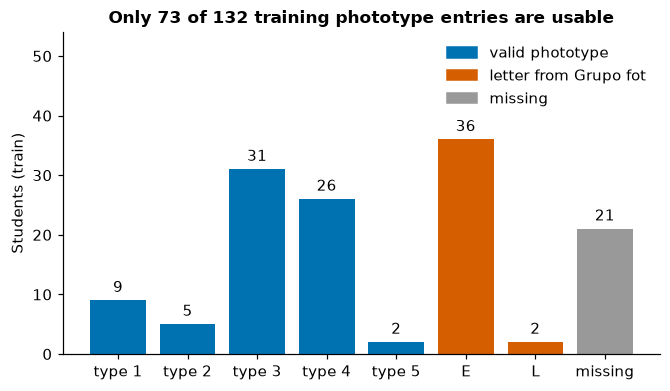

usable phototype in train: 73 of 132; test: 15 of 24


In [7]:
counts = (X_train_raw["fototipo"].fillna("missing")
          .str.replace("Fototipo ", "type ", regex=False).value_counts())
order = ["type 1", "type 2", "type 3", "type 4", "type 5", "E", "L", "missing"]
counts = counts.reindex(order).fillna(0).astype(int)
kind = ["valid phototype"] * 5 + ["letter from Grupo fot"] * 2 + ["missing"]
colors = {"valid phototype": BLUE, "letter from Grupo fot": VERMILLION, "missing": MISSING_GRAY}

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(counts.index, counts.values, color=[colors[k] for k in kind])
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.8, str(v), ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.5)
ax.set_ylabel("Students (train)")
ax.set_title("Only 73 of 132 training phototype entries are usable")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()],
          labels=list(colors), loc="upper right")
save_fig(fig, "02_phototype")
plt.show()

usable = int(counts[:5].sum())
print(f"usable phototype in train: {usable} of {len(X_train)}; test: {int(X_test['phototype'].notna().sum())} of {len(X_test)}")

Only 73 of 132 training students (15 of 24 in test) have a usable phototype. That is much more missing than the 17 % estimated in notebook 01, because the 38 mixed-up entries count as missing too. The meaning of `E` and `L` in `Grupo fot` is unknown. Filling nearly half of a column with the median is a strong assumption, so keeping or dropping the feature stays open (B9 in `docs/assumptions.md`): it will be compared inside cross-validation, with it, without it, and with a missing-value flag, and never by checking its link with the labels first.

## 6. The engineered yes/no features

The table counts the students with each yes/no feature equal to 1, in train and in test. It only checks that every flag is populated and that train and test look alike.

In [8]:
binary = [c for c in FEATURE_COLUMNS if X_train[c].dropna().isin([0, 1]).all()]
flags = pd.concat([X_train[binary].sum().astype(int).rename(f"train (n={len(X_train)})"),
                   X_test[binary].sum().astype(int).rename(f"test (n={len(X_test)})")], axis=1)
flags.index.name = "students with value 1"
flags

,train (n=132),test (n=24)
students with value 1,,
female,97,12
foreign_ancestors,14,4
outdoor_much,63,10
indoor_much,8,1
father_myopic,59,14
mother_myopic,54,14
siblings_myopic,59,10
relatives_unknown,5,1
family_mm_yes,13,3


Every flag occurs in both train and test. Two are rare, `indoor_much` and `relatives_unknown`, and will carry little weight. With only 24 test students, the counts in train and test look comparable.

## 7. Redundancy that remains

Strongly correlated features make linear models unstable and make importances hard to read. We compute the Spearman correlation between the 33 features and order the matrix by hierarchical clustering so that similar features sit together. The matrix is also checked for exact linear dependence (rank and condition number). Nothing is dropped here: with 132 students, choosing between near-duplicates is better left to regularisation and to the model comparison, and it never uses the labels.

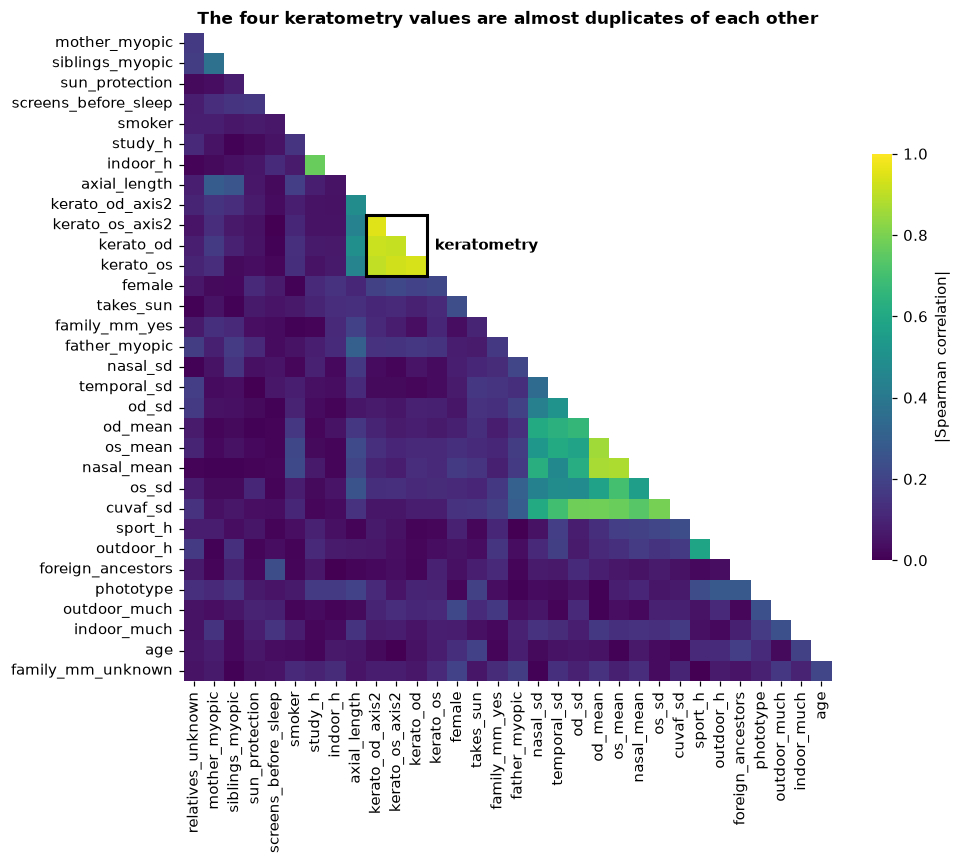

standardised training matrix: rank 33 of 33 columns, condition number 22


|r|
kerato_os_axis2 kerato_od_axis2  0.95
kerato_os       kerato_od        0.94
                kerato_os_axis2  0.93
kerato_od       kerato_od_axis2  0.92
                kerato_os_axis2  0.91
kerato_os       kerato_od_axis2  0.91
nasal_mean      os_mean          0.88
                od_mean          0.87
os_mean         od_mean          0.86
cuvaf_sd        os_sd            0.79
                od_mean          0.79
                od_sd            0.78
                os_mean          0.77
indoor_h        study_h          0.77
cuvaf_sd        nasal_mean       0.74
os_sd           os_mean          0.70

In [9]:
corr = X_train.corr(method="spearman").abs()
order = leaves_list(linkage(squareform(1 - corr.fillna(0).to_numpy(), checks=False), "average"))
ordered = corr.iloc[order, order]
position = {name: i for i, name in enumerate(ordered.index)}

blocks = {"keratometry": ["kerato_od", "kerato_os", "kerato_od_axis2", "kerato_os_axis2"]}
fig, ax = plt.subplots(figsize=(9.5, 8))
shown = ordered.iloc[1:, :-1]          # drop the empty first row and last column of the lower triangle
sns.heatmap(shown, mask=np.triu(np.ones_like(shown, dtype=bool), k=1), cmap=SEQUENTIAL_CMAP,
            vmin=0, vmax=1, square=True, linewidths=0, ax=ax,
            cbar_kws={"label": "|Spearman correlation|", "shrink": 0.6})
for label, names in blocks.items():
    idx = sorted(position[n] for n in names)
    assert idx == list(range(idx[0], idx[-1] + 1)), f"{label} is not contiguous in the clustered order"
    size = len(idx) - 1
    ax.add_patch(Rectangle((idx[0], idx[0]), size, size, fill=False, edgecolor="black", lw=2))
    ax.text(idx[0] + size + 0.4, idx[0] + size / 2, label, ha="left", va="center", fontweight="bold")
ax.set_title("The four keratometry values are almost duplicates of each other")
save_fig(fig, "02_feature_correlation")
plt.show()

Z = make_preprocessor(scale=True).fit_transform(X_train).to_numpy()
singular = np.linalg.svd(Z, compute_uv=False)
print(f"standardised training matrix: rank {np.linalg.matrix_rank(Z)} of {Z.shape[1]} columns, "
      f"condition number {singular[0] / singular[-1]:.0f}")

pairs = (ordered.where(np.tril(np.ones(ordered.shape, dtype=bool), k=-1)).stack()
         .loc[lambda s: s > 0.7].sort_values(ascending=False).round(2))
pairs.rename("|r|").to_frame()

No exact dependence is left: the standardised matrix has full rank (33 of 33) and a small condition number. One group is almost duplicated, the four keratometry values (0.91 to 0.95). Next come the three retinal means (0.86 to 0.88), the spread columns with the means (up to 0.79) and indoor with study hours (0.77), which follow from how those features are built. The rest are only loosely related. *Decision: keep all 33.* Linear models will be regularised, and importances inside a group will not be interpreted one by one.

## 8. The preprocessing contract: what is learned from data

Missing values will be filled with the median of the training rows and, for the models that need it, the features will be standardised. `make_preprocessor` does this and must be the first step of every model pipeline, so that each cross-validation fold learns its own medians and never sees its validation rows. The cell below fits it on the training rows only, checks that the test set comes out without missing values and with the columns in the expected order, and compares with the median we would get if the test rows leaked in.

In [10]:
prep = make_preprocessor(scale=True).fit(X_train)       # fitted on the 132 training rows only
X_test_ready = prep.transform(X_test)
assert not X_test_ready.isna().any().any()
assert list(X_test_ready.columns) == FEATURE_COLUMNS

with_missing = list(X_train.columns[X_train.isna().any()])
train_medians = pd.Series(prep.named_steps["impute"].statistics_, index=FEATURE_COLUMNS)[with_missing]
both = pd.concat([X_train, X_test])[with_missing].median()
pd.DataFrame({"median used (train only)": train_medians, "median if test were included": both}).round(2)

,median used (train only),median if test were included
phototype,3.0,3.0


The test set is completely filled using training statistics only. For phototype the two medians happen to be identical, so a leak would change nothing here. The rule still matters for the later pipelines, where the validation fold must be excluded as well.

## 9. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | 49 raw columns: 1 empty, 12 exact or almost exact combinations of others, 7 judged not useful | `clean_features` drops the 20 and builds 33 numeric features, row by row |
| 2 | The equalities were checked on train and test | All hold in train; one test student's CUVAF mean is inconsistent (column dropped); ratio values for 5 students unexplained and not used |
| 3 | The letters in `fototipo` are the values of `Grupo fot`, so `phototype` is mostly missing | Kept for now; keep, drop or flag it inside cross-validation (B9) |
| 4 | No exact dependence left; keratometry values are almost duplicates | Keep all 33; regularise linear models; do not read importances inside a group |
| 5 | Anything learned from data must stay out of the validation folds | `make_preprocessor` is the first step of every pipeline |

**Not decided here:** the metric used to choose models (B1), the handling of the 8 inconsistent labels (B2) and the phototype question (B9).

**Next notebook (03):** baselines and the validation scheme. It needs B1 settled first.